<center><h1>Last_First_HW4</h1></center>
<br>
<br>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from numpy.ma.core import indices
from sklearn.neighbors import KNeighborsRegressor
from tornado.gen import multi
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import os


Get the AReM Data Set

In [6]:
data_path = r'./AReM'

### (b) Splitting Data

### (c) Feature Extraction

In [3]:
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
time_series = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
features = ["min", "max", "mean",  "median", "std", "first_quartile", "third_quartile"]

all = []

for activity in activities:
    folder = os.path.join(data_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        for i , col in enumerate(time_series, start=1):
            instances[f'min{i}'] = df[col].min()
            instances[f'max{i}'] = df[col].max()
            instances[f'mean{i}'] = df[col].mean()
            instances[f'median{i}'] = df[col].median()
            instances[f'std{i}'] = df[col].std()
            instances[f"first_quartile{i}"] = df[col].quantile(0.25)
            instances[f"third_quartile{i}"] = df[col].quantile(0.75)
        all.append(instances)
feature_df = pd.DataFrame(all)
feature_df.head()


,activity,file,min1,max1,mean1,median1,std1,first_quartile1,third_quartile1,min2,...,std5,first_quartile5,third_quartile5,min6,max6,mean6,median6,std6,first_quartile6,third_quartile6
0,bending1,dataset1.csv,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

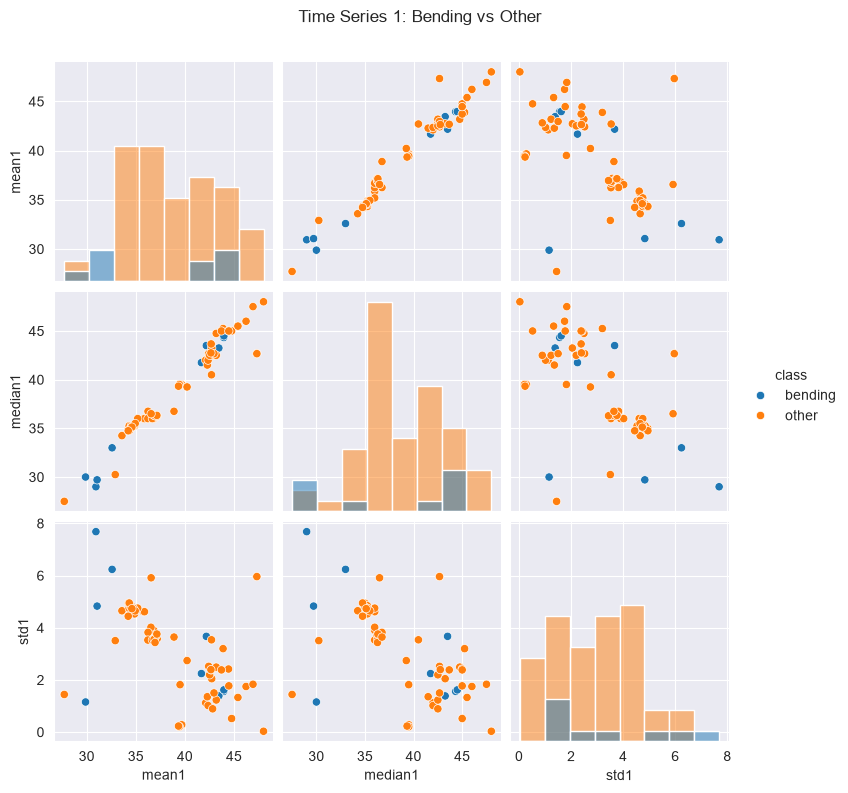

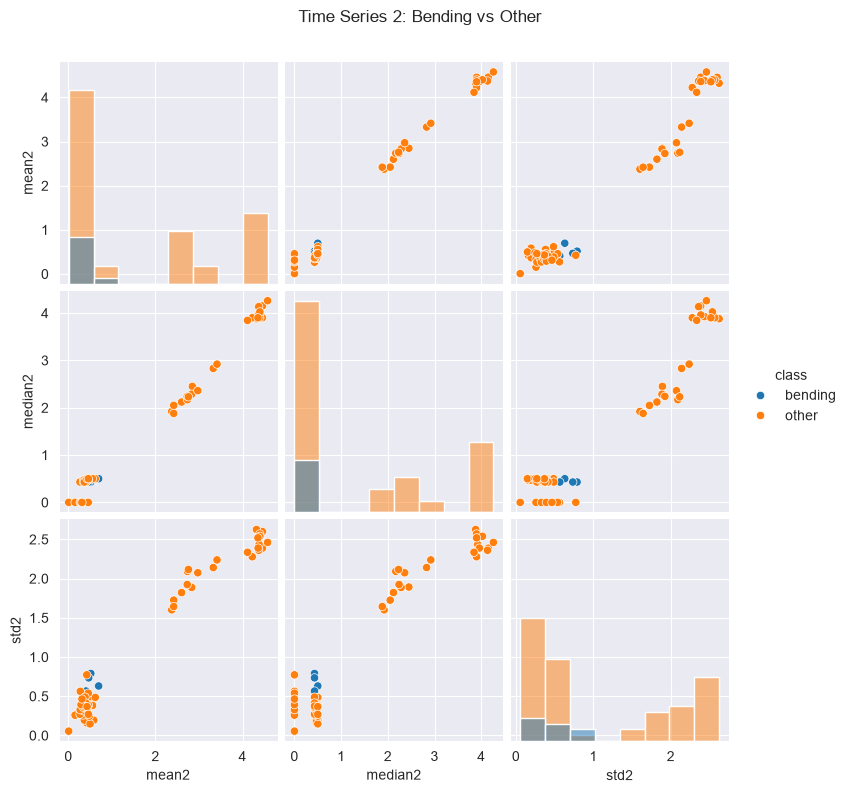

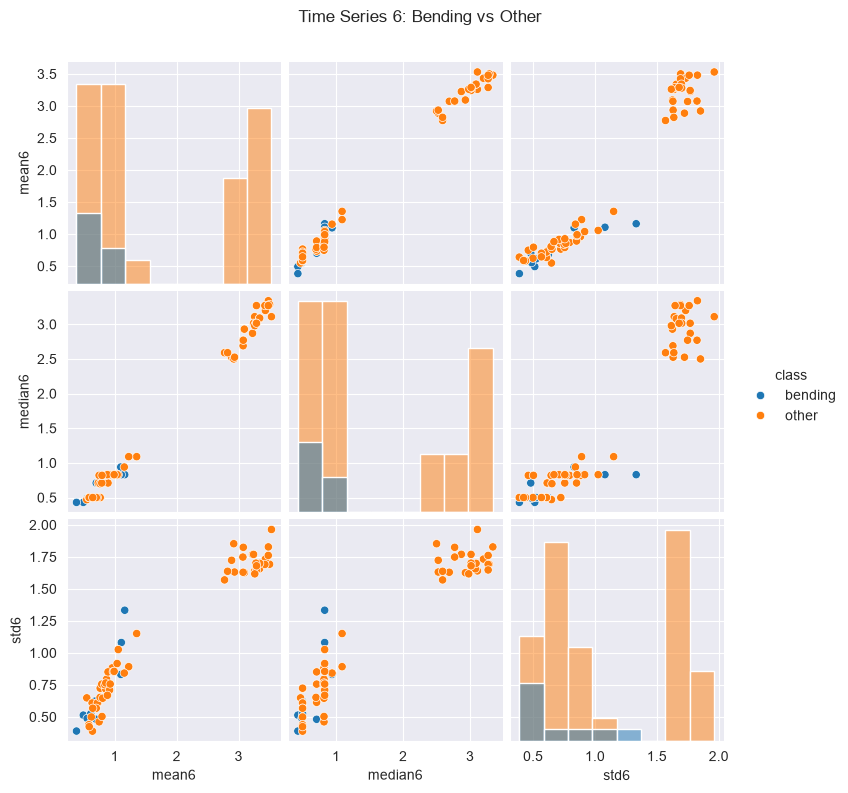

In [16]:
train_path = os.path.join("Train_set")

train_features = []

for activity in activities:
    folder = os.path.join(train_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        for i , col in enumerate(time_series, start=1):
            instances[f'min{i}'] = df[col].min()
            instances[f'max{i}'] = df[col].max()
            instances[f'mean{i}'] = df[col].mean()
            instances[f'median{i}'] = df[col].median()
            instances[f'std{i}'] = df[col].std()
            instances[f"first_quartile{i}"] = df[col].quantile(0.25)
            instances[f"third_quartile{i}"] = df[col].quantile(0.75)
        train_features.append(instances)
feature_df = pd.DataFrame(train_features)
# feature_df.head()

feature_df["class"] = feature_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)


for i in [1, 2, 6]:
    selected = [f"mean{i}", f"median{i}", f"std{i}"]

    sns.pairplot(feature_df, vars = selected, hue = "class", diag_kind="hist")
    plt.suptitle(f"Time Series {i}: Bending vs Other", y=1.05)
    plt.show()

#### ii. Splitted Plots

In [18]:
split = []
for activity in activities:
    folder = os.path.join(train_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        mid = len(df) //2
        part1 = df.iloc[:mid]
        part2 = df.iloc[mid:]

        for i in [1,2,6]:
            col = time_series[i-1]
            instances[f"mean{i}_part1"] = part1[col].mean()
            instances[f"mean{i}_part2"] = part2[col].mean()
            instances[f"median{i}_part1"] = part1[col].median()
            instances[f"median{i}_part2"] = part2[col].median()
            instances[f"std{i}_part1"] = part1[col].std()
            instances[f"std{i}_part2"] = part2[col].std()
        split.append(instances)
split_df = pd.DataFrame(split)
split_df.head()


(69, 20)

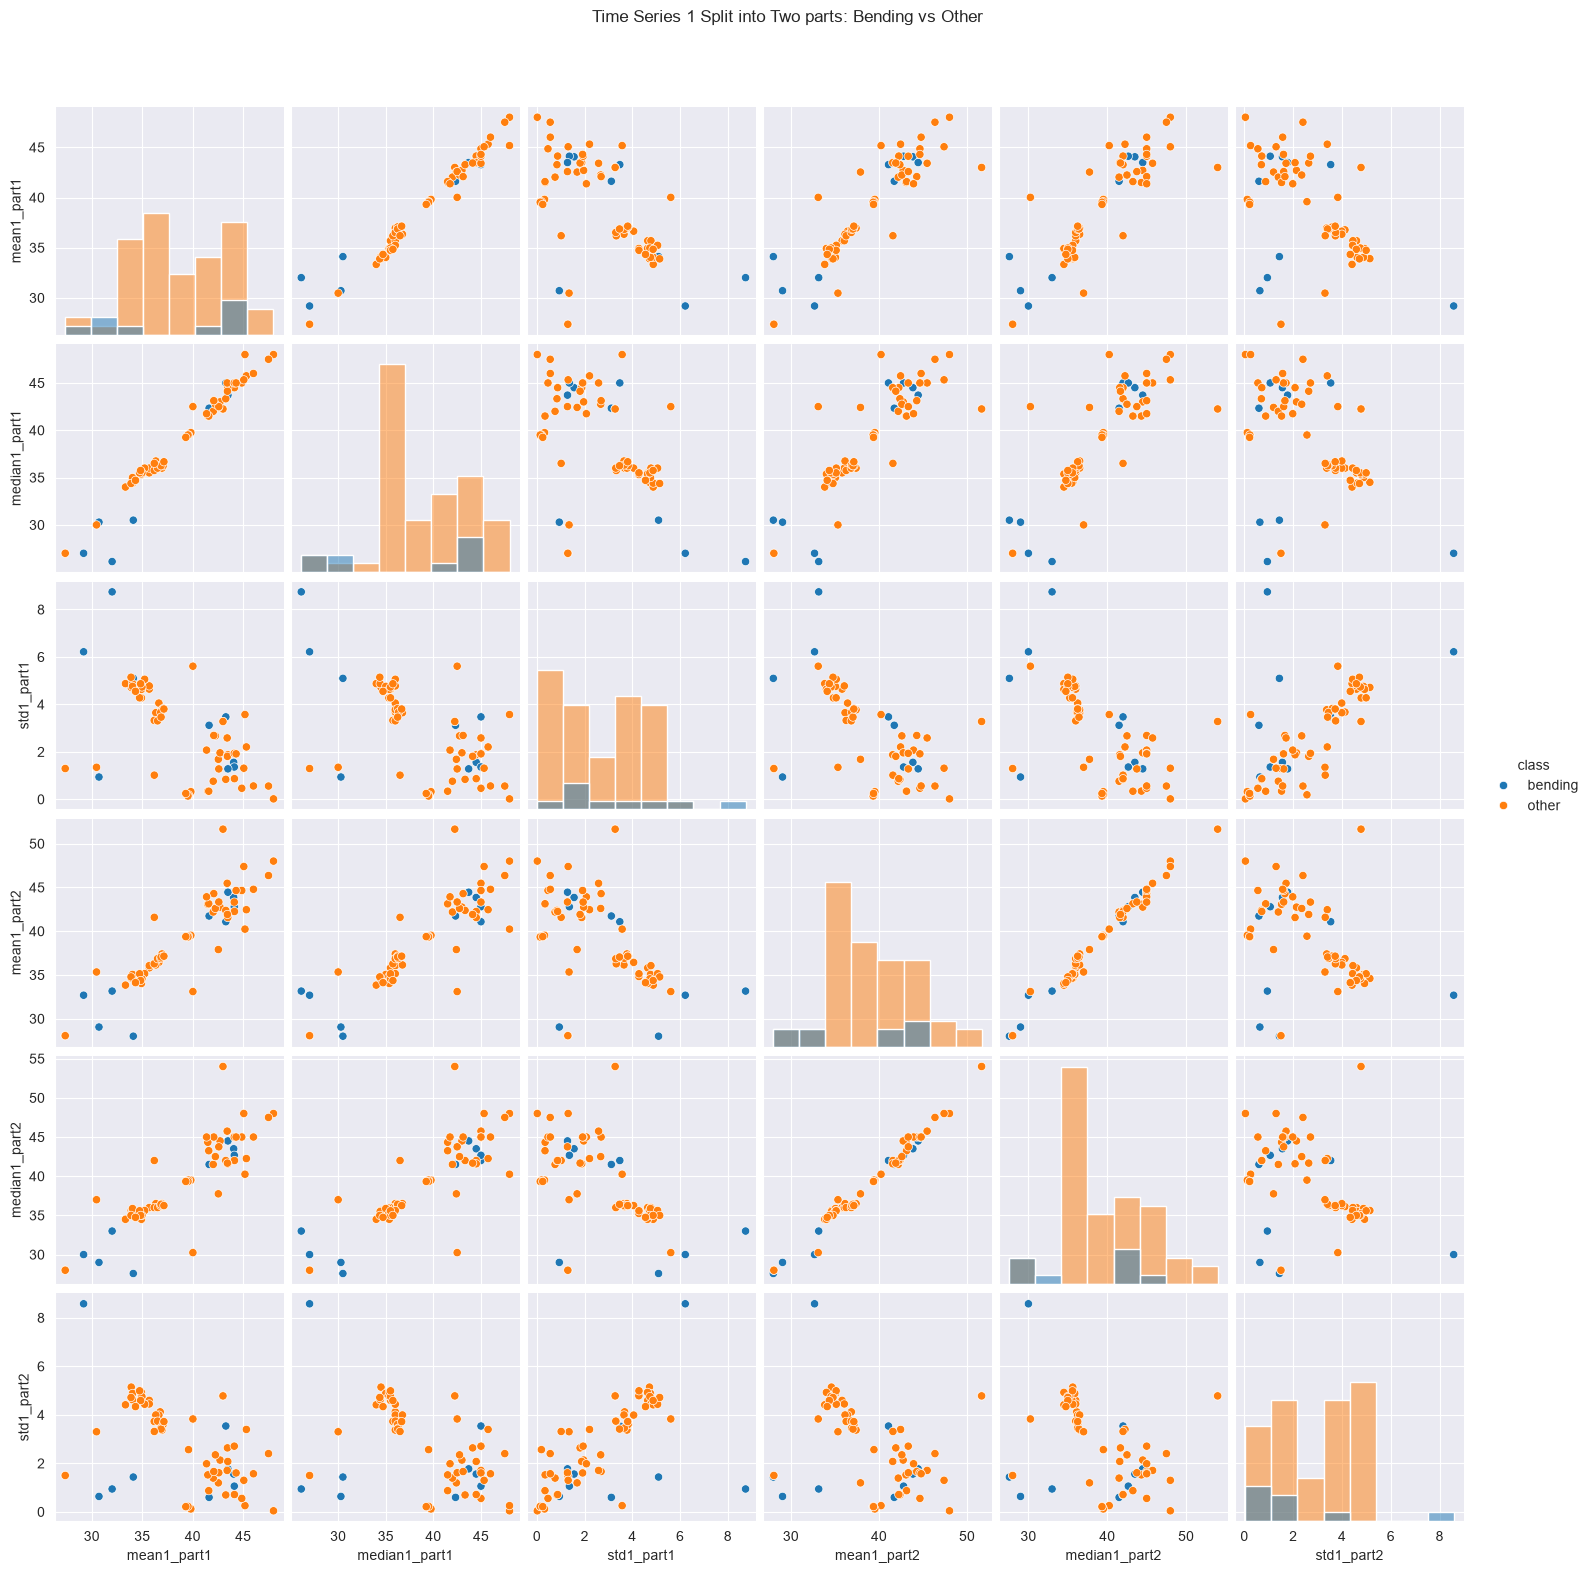

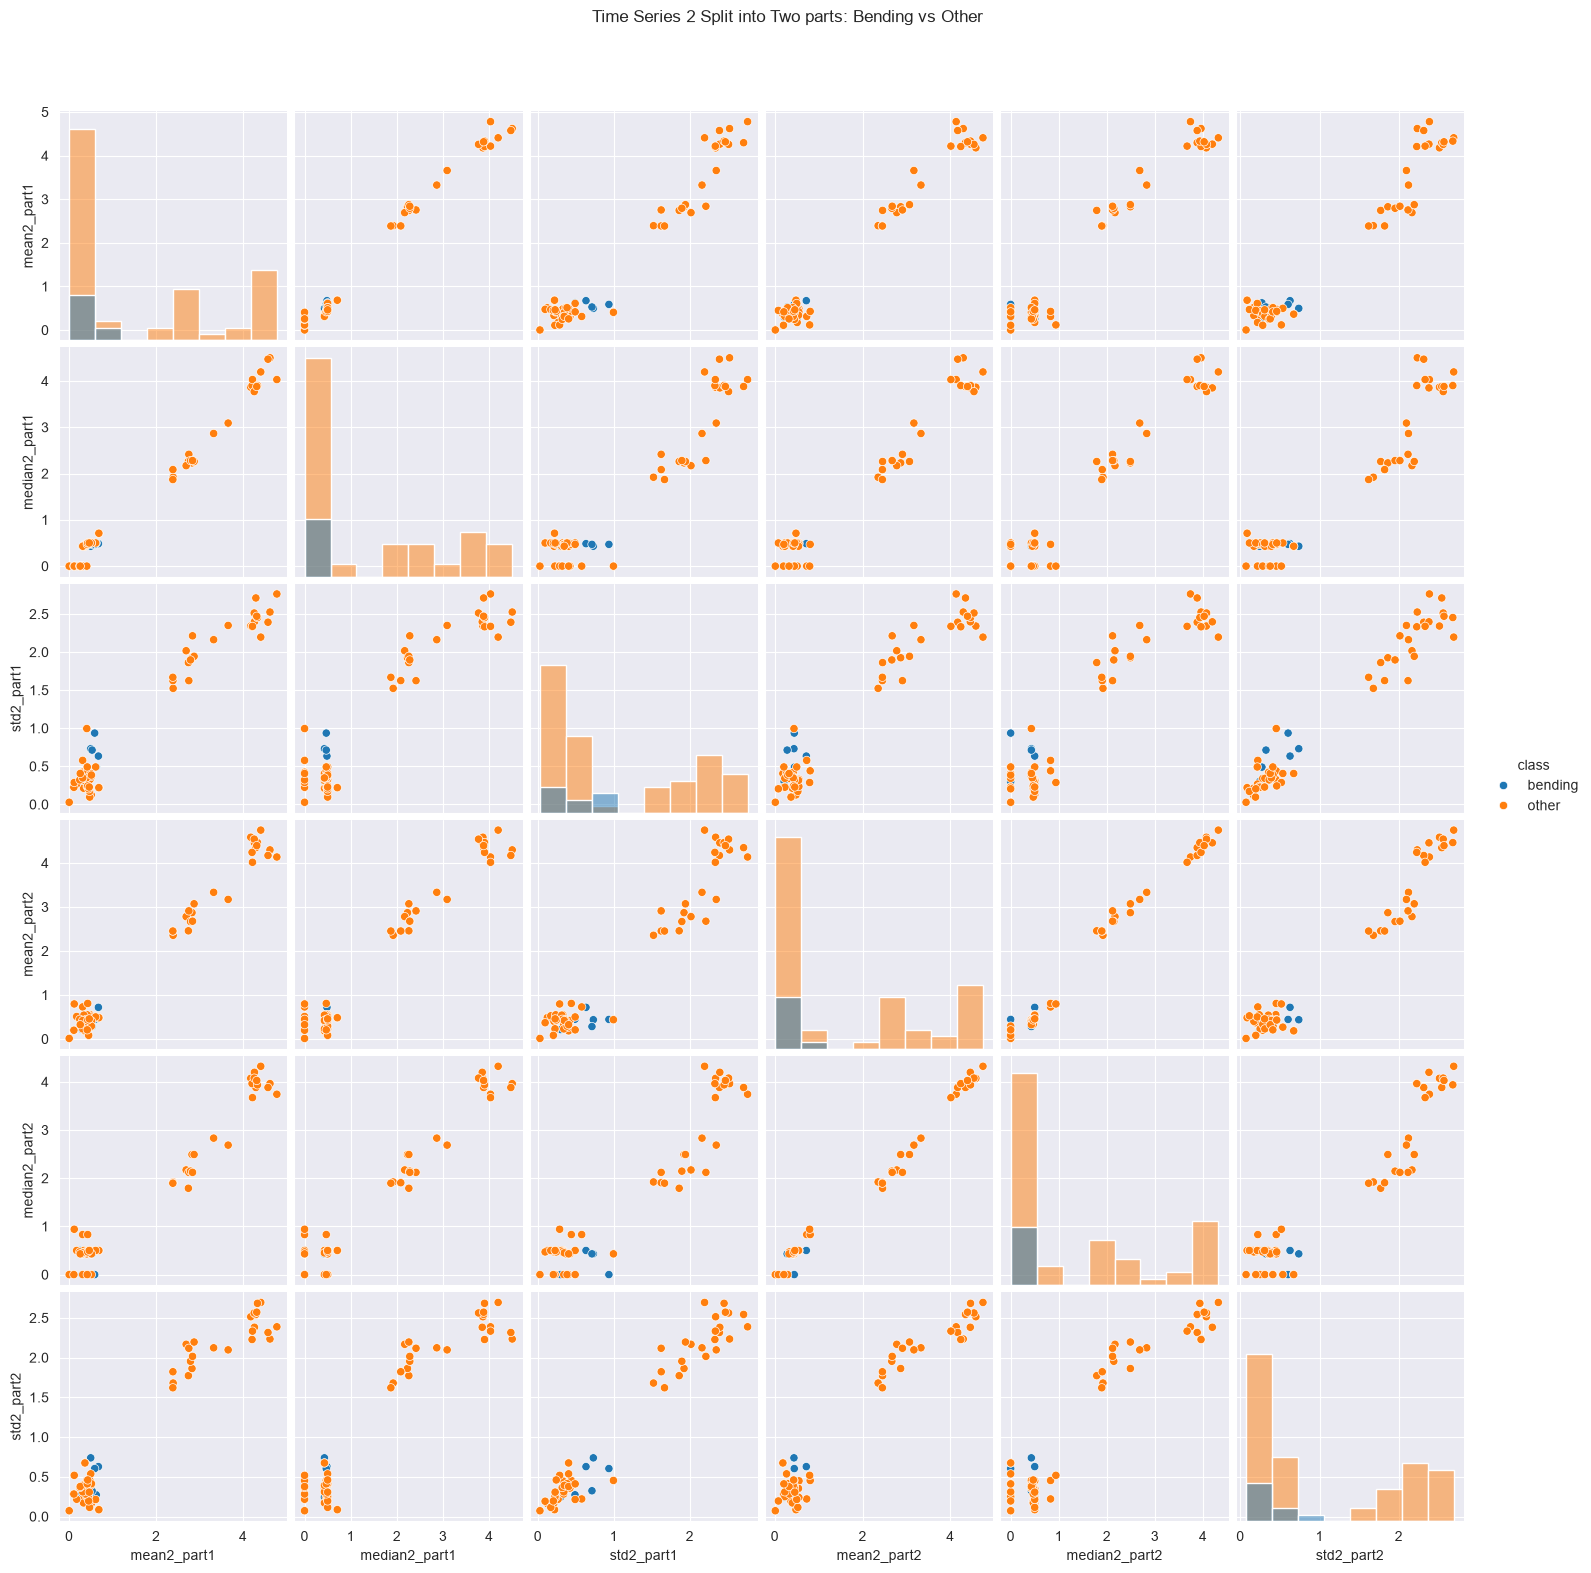

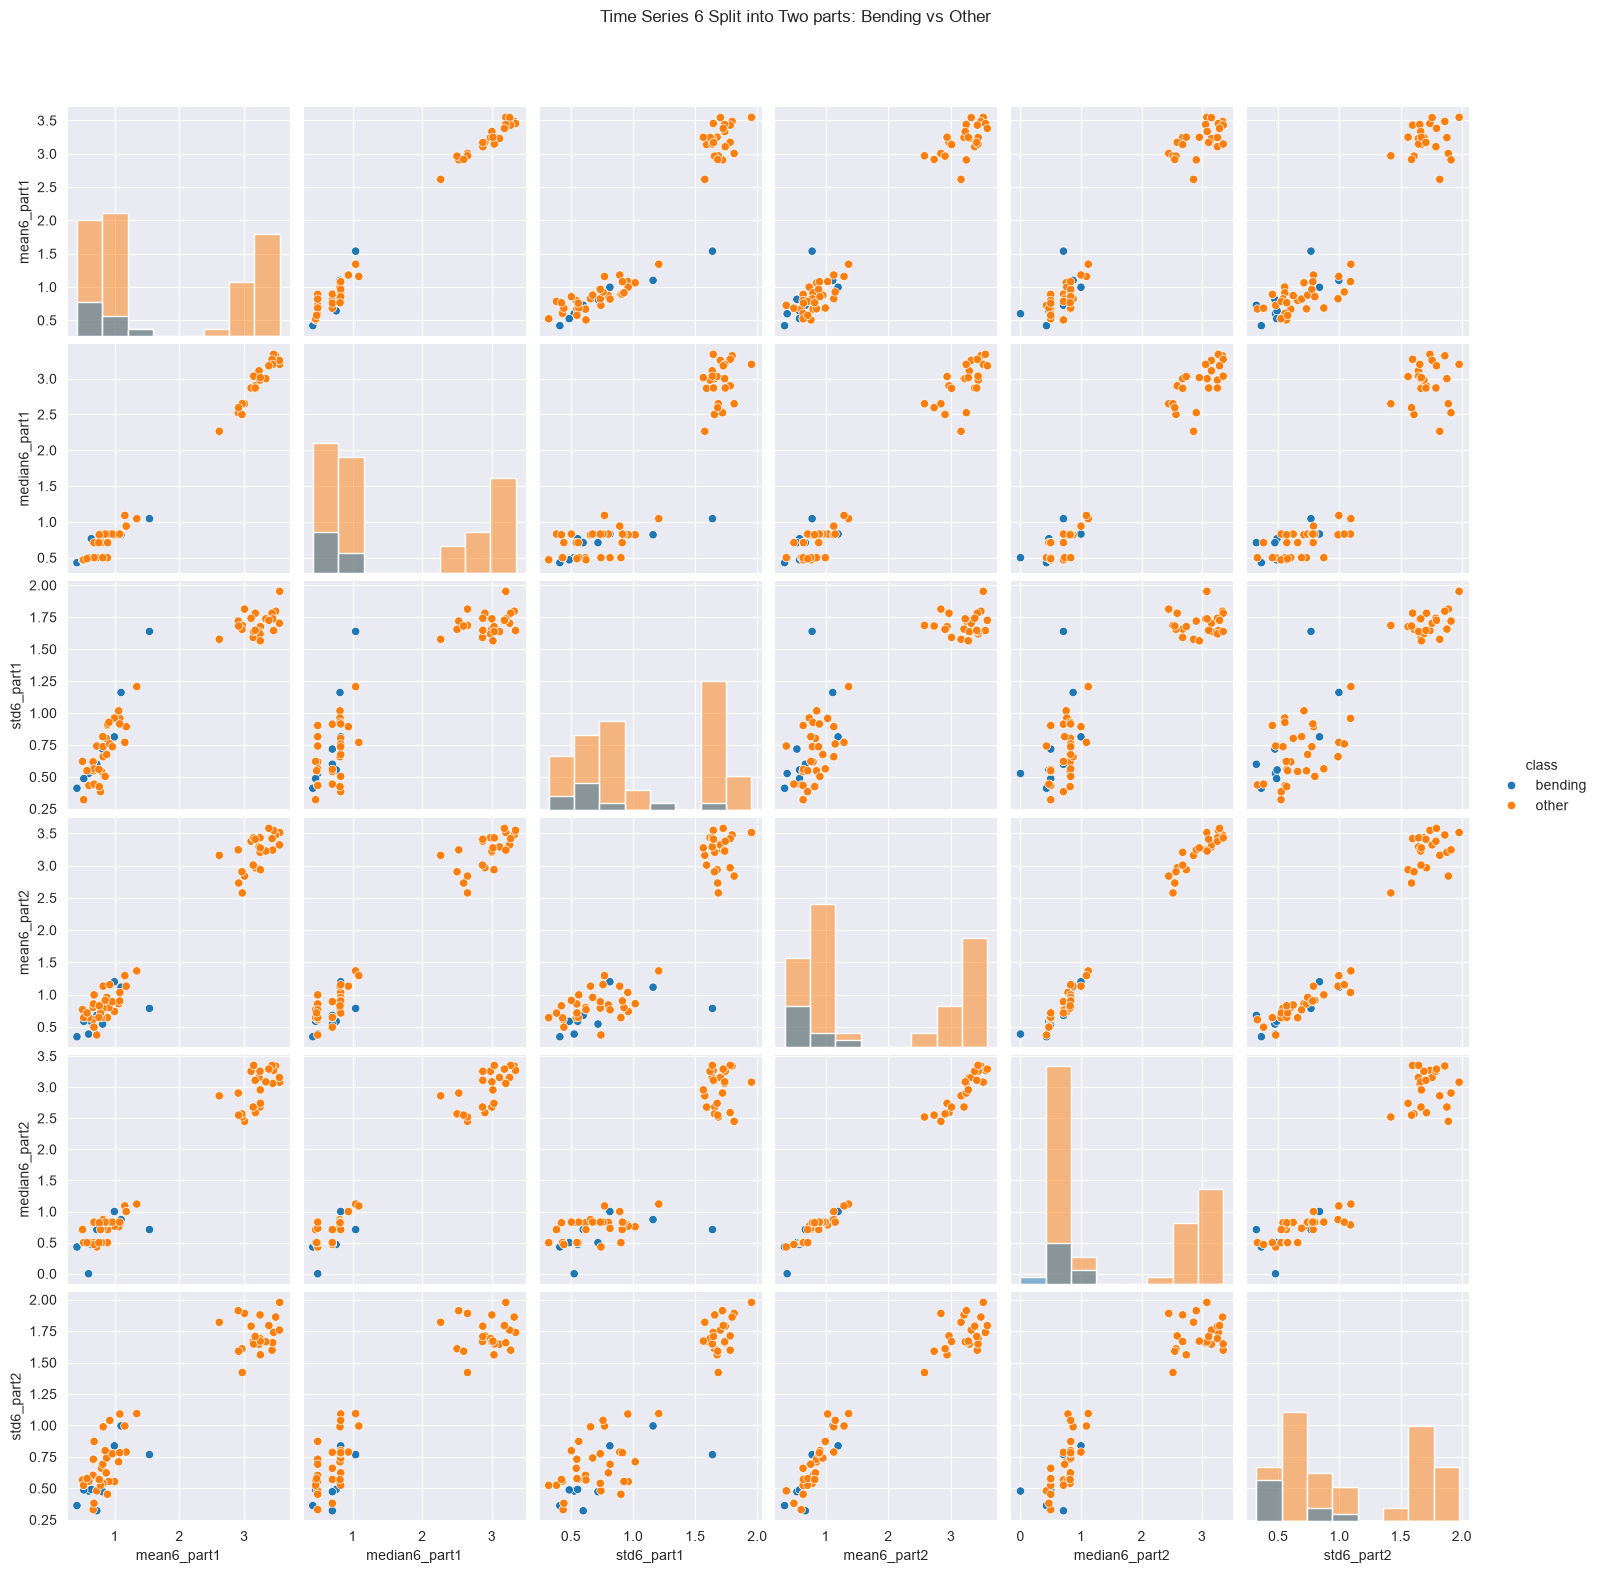

In [21]:
split_df["class"] = split_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)

for i in [1, 2, 6]:
    selected = [f"mean{i}_part1", f"median{i}_part1", f"std{i}_part1",f"mean{i}_part2", f"median{i}_part2",f"std{i}_part2"]

    sns.pairplot(split_df, vars =selected, hue = "class", diag_kind="hist")
    plt.suptitle(f"Time Series {i} Split into Two parts: Bending vs Other", y=1.05)
    plt.show()

After splitting each time series into two equal parts, the overall separation between bending and other activities is similar to what we got in (i). With the split we have additional features which provides us more detailed information about with-in instance variation but there is no considerable visual changes in class separation. In both sections' result, for time series 1 and 6 we get substantial overlaps and scatter between bending and other activities, while time series 2 we can see some relatively clear separation between them.

#### iii. Time Series Segments

In [45]:
def extract_features (l):
    extract = []
    for activity in activities:
        folder = os.path.join(train_path, activity)
        for file in os.listdir(folder):
            if not file.endswith('.csv'):
                continue
            file_path = os.path.join(folder, file)
            df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
            instances = {"activity": activity, "file" : file}

            split_indices = np.array_split(np.arange(len(df)), l)

            for num, indices in enumerate(split_indices, start=1):
                part = df.iloc[indices]

                for i, col in enumerate(time_series, start=1):
                    instances[f"min{i}_part{num}"] = part[col].min()
                    instances[f"max{i}_part{num}"] = part[col].max()
                    instances[f"mean{i}_part{num}"] = part[col].mean()
                    instances[f"median{i}_part{num}"] = part[col].median()
                    instances[f"std{i}_part{num}"] = part[col].std()
                    instances[f"first_quartile{i}_part{num}"] = part[col].quantile(0.25)
                    instances[f"third_quartile{i}_part{num}"] = part[col].quantile(0.75)
            if activity in ["bending1", "bending2"]:
                instances["class"] = 1
            else:
                instances["class"] = 0
            extract.append(instances)
    return pd.DataFrame(extract)



In [61]:
from sklearn .feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn import datasets
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
p_list = list(range(1,20))

for l in range(1,21):
    # print(f"l = {l}")

    df = extract_features(l)
    X = df.drop(columns=["activity", "file", "class"])
    y = df["class"]
    n_features = X.shape[1]

    for p in p_list:
        if p > n_features:
            continue
        scores =[]

        for train_index, val_index in cv.split(X,y):
            X_train, X_val = X.iloc[train_index], X.iloc[val_index]
            y_train, y_val = y.iloc[train_index], y.iloc[val_index]
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")

            rfe = RFE(estimator=model, n_features_to_select = p,step=0.1)

            X_train_rfe = rfe.fit_transform(X_train_scaled, y_train)
            X_val_rfe = rfe.transform(X_val_scaled)

            final_log = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
            final_log.fit(X_train_rfe, y_train)

            y_pred = final_log.predict(X_val_rfe)
            scores.append(accuracy_score(y_val, y_pred))

        results.append({"l":l, "p":p, "mean_cv_accuracy":np.mean(scores)})

result_df = pd.DataFrame(results)
result_df = result_df.sort_values(by =["mean_cv_accuracy", "p","l"], ascending=[False, True, True])
result_df.head(10)

,l,p,mean_cv_accuracy
210,12,2,0.985714
2,1,3,0.985714
12,1,13,0.985714
18,1,19,0.985714
43,3,6,0.971429
195,11,6,0.971429
44,3,7,0.971429
196,11,7,0.971429
45,3,8,0.971429
46,3,9,0.971429


In [63]:
best_l =12
best_p = 2
best_df = extract_features(best_l)
X = best_df.drop(columns=["activity", "file", "class"])
y = best_df["class"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
rfe = RFE(estimator=model, n_features_to_select = best_p, step=0.1)
X_rfe = rfe.fit_transform(X_scaled, y)
selected_features = X.columns[rfe.support_]
print("Selected features:", selected_features)
final_log = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
final_log.fit(X_rfe, y)
print("Intercept:", final_log.intercept_)
print("Coefficients:", final_log.coef_)


Selected features: Index(['first_quartile5_part2', 'first_quartile1_part3'], dtype='str')
Intercept: [-10.26765943]
Coefficients: [[10.93020423 -2.25038545]]


#### iv. Confusion Matrix

#### v. Test Classifier

#### vi. Separation

#### vii. Imbalance

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

## 4. ISLR 4.8.7

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9